In [71]:
from pathlib import Path
import json
import re

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D


In [72]:
# ============================================================
# CONFIGURATION
# ============================================================

data_version = "v1.2.1"
data_campaign = "c1"

measurements = [
    "am_HS1_top_dlt",
    "am_HS6_top_dlt",
]

results_root = (
    Path("/global/u2/r/ritaferi/HADES_DATA")
    / "O60_experimental_pygama"
    / data_version
    / data_campaign
)

runs = ["run0001"]#, "run0002", "run0003"]

run_colors = {
    "run0001": "navy",
    "run0002": "orange",
    "run0003": "deepskyblue",
}

run_offsets = {
    "run0001": -0.22,
    "run0002": 0.0,
    "run0003": 0.22,
}

# True: salva anche le figure.
save_plots = True

output_dir = results_root / "comparison_measurements"

if save_plots:
    output_dir.mkdir(parents=True, exist_ok=True)


In [73]:


# ============================================================
# HELPERS
# ============================================================

def finite_number(value):
    try:
        value = float(value)
    except (TypeError, ValueError):
        return None

    return value if np.isfinite(value) else None


def get_ratio(record, method):
    """Restituisce rapporto e incertezza dal record JSON."""
    if method == "fit":
        ratio = record.get("ratio") or {}
    elif method == "counting":
        ratio = (
            record.get("ratio_counting")
            or (record.get("counting_method") or {}).get("ratio")
            or {}
        )
    else:
        raise ValueError(f"Metodo non riconosciuto: {method}")

    if not isinstance(ratio, dict):
        return None, None

    value = finite_number(ratio.get("value"))
    error = finite_number(ratio.get("error"))

    if error is not None and error < 0:
        error = None

    return value, error


In [74]:


# ============================================================
# LOAD BOTH MEASUREMENTS
# ============================================================

results_by_measurement = {}

for measurement in measurements:
    path = results_root / measurement / "all_results.json"

    if not path.is_file():
        print(f"File mancante: {path}")
        continue

    with path.open(encoding="utf-8") as stream:
        results_by_measurement[measurement] = json.load(stream)

    print(f"Caricato: {path}")

if not results_by_measurement:
    raise FileNotFoundError(
        f"Nessun all_results.json trovato in {results_root}"
    )


# Stesso ordine dei detector in tutti i pannelli.
detectors = sorted({
    detector
    for results in results_by_measurement.values()
    for detector, detector_runs in results.items()
    if any(
        get_ratio(detector_runs.get(run) or {}, method)[0] is not None
        for run in runs
        for method in ("fit", "counting")
    )
})

if not detectors:
    raise ValueError("Nessun rapporto disponibile nei file caricati.")

positions = {
    detector: index
    for index, detector in enumerate(detectors)
}


Caricato: /global/u2/r/ritaferi/HADES_DATA/O60_experimental_pygama/v1.2.1/c1/am_HS1_top_dlt/all_results.json
Caricato: /global/u2/r/ritaferi/HADES_DATA/O60_experimental_pygama/v1.2.1/c1/am_HS6_top_dlt/all_results.json


In [75]:
results_by_measurement['am_HS1_top_dlt']['V06643A']['run0001']['counting_method']

{'60': {'sigma_keV': {'N60': 0.24850953018822422},
  'sigma_source': 'detector YAML eres_quadratic',
  'n_sigma': 3.0,
  'windows': {'left': {'requested_range_keV': [56.5, 57.5],
    'actual_range_keV': [56.5, 57.5],
    'width_keV': 1.0,
    'n_bins': 10,
    'counts': 34781.0},
   'right': {'requested_range_keV': [61.5, 62.5],
    'actual_range_keV': [61.5, 62.5],
    'width_keV': 1.0,
    'n_bins': 10,
    'counts': 9048.0},
   'N60': {'requested_range_keV': [58.754471409435325, 60.245528590564675],
    'actual_range_keV': [58.7, 60.300000000000004],
    'width_keV': 1.6000000000000014,
    'n_bins': 16,
    'energy_keV': 59.5,
    'sigma_keV': 0.24850953018822422,
    'counts': 1769770.0}},
  'background_density_counts_per_keV': 21914.5,
  'peaks': {'N60': {'value': 1734706.8,
    'error': 1340.8283111569506,
    'gross_counts': 1769770.0,
    'background_counts': 35063.20000000003,
    'background_scale': 0.8000000000000007}},
  'peak_order': ['N60'],
  'covariance': [[1797820.56]

Plot salvato: /global/u2/r/ritaferi/HADES_DATA/O60_experimental_pygama/v1.2.1/c1/comparison_measurements/am_HS1_top_dlt_ratios_fit_counting_vs_detector.png


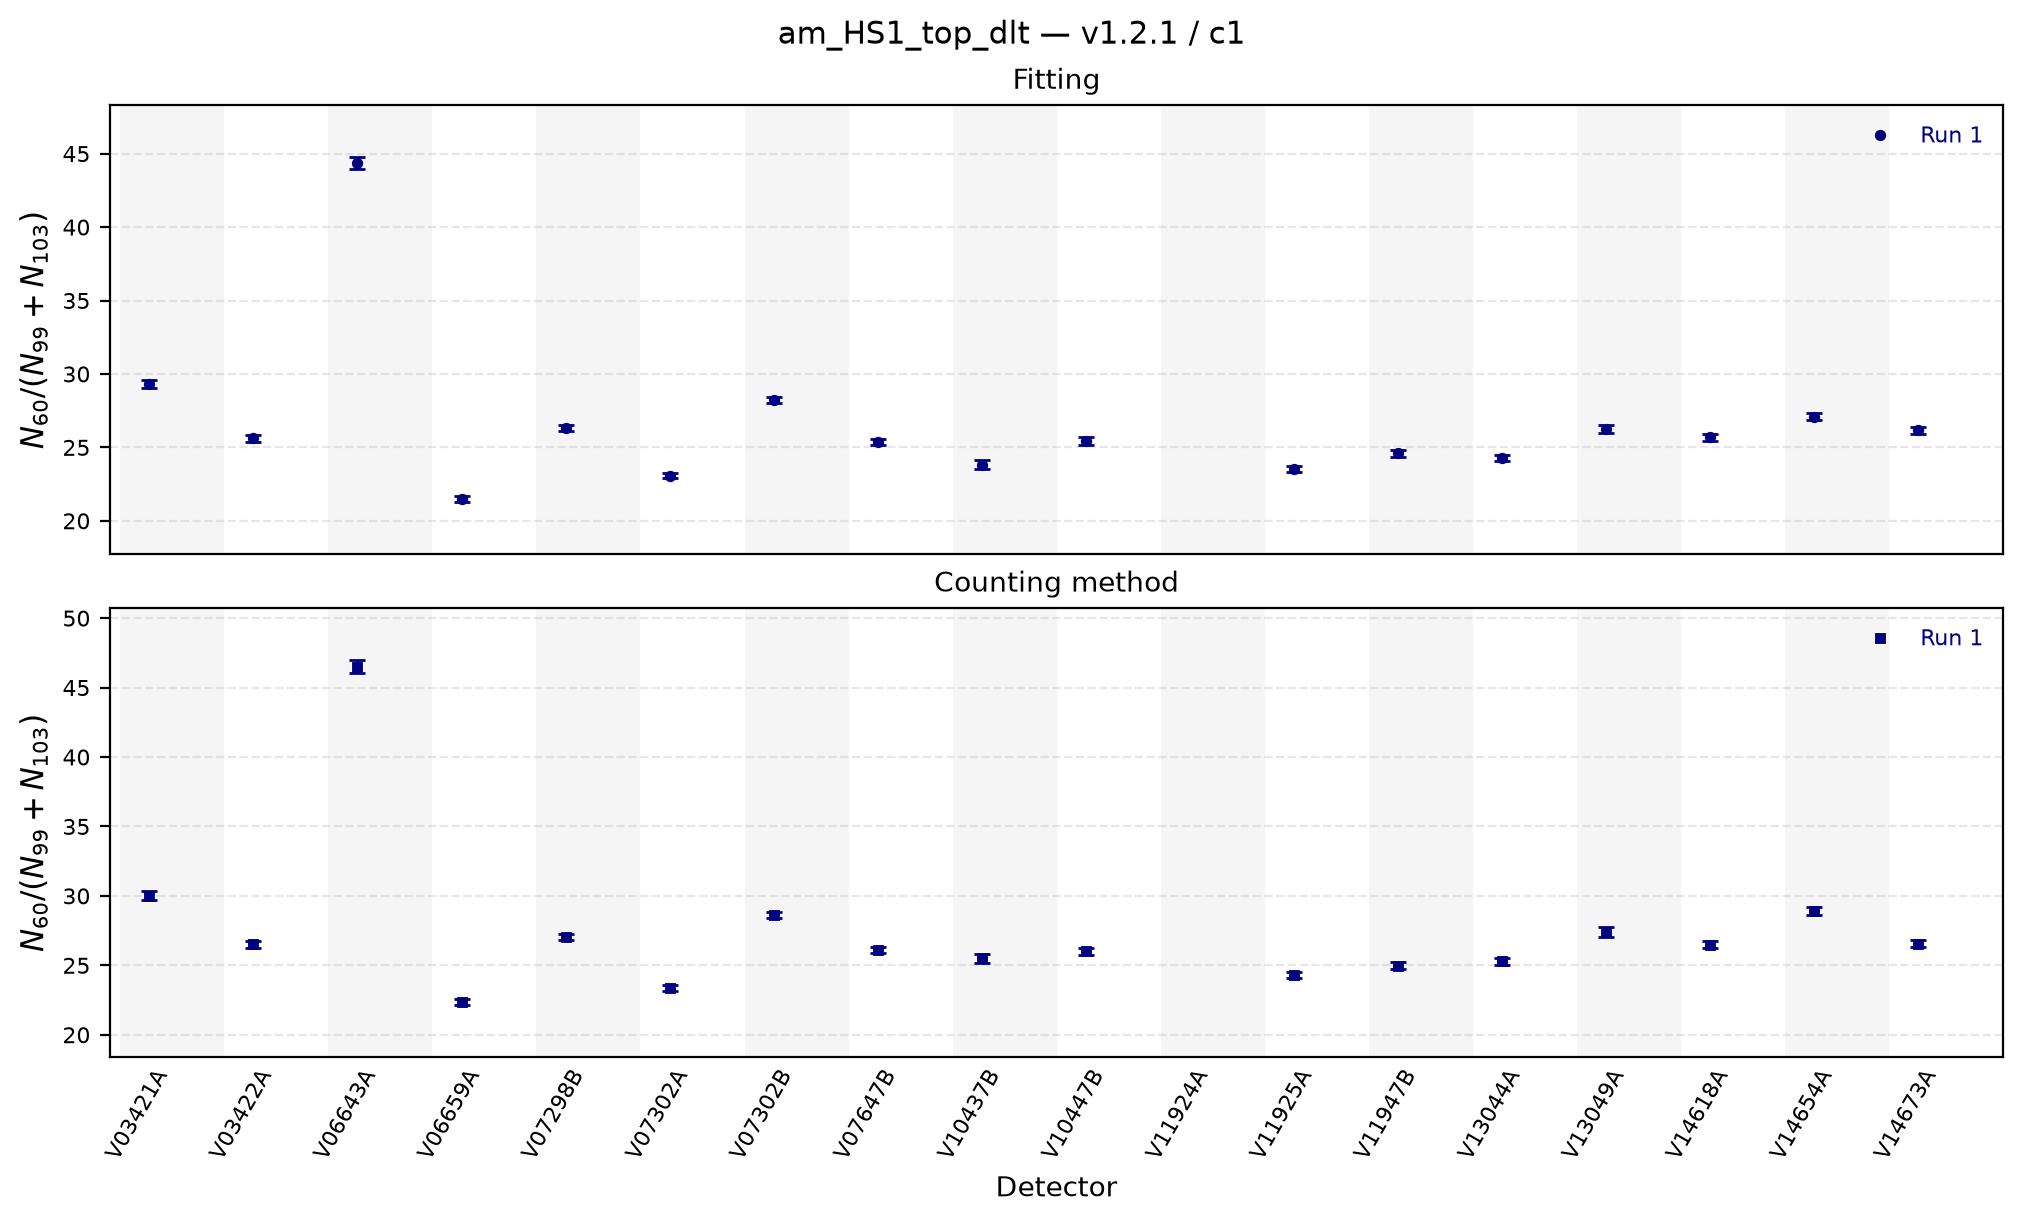

Plot salvato: /global/u2/r/ritaferi/HADES_DATA/O60_experimental_pygama/v1.2.1/c1/comparison_measurements/am_HS6_top_dlt_ratios_fit_counting_vs_detector.png


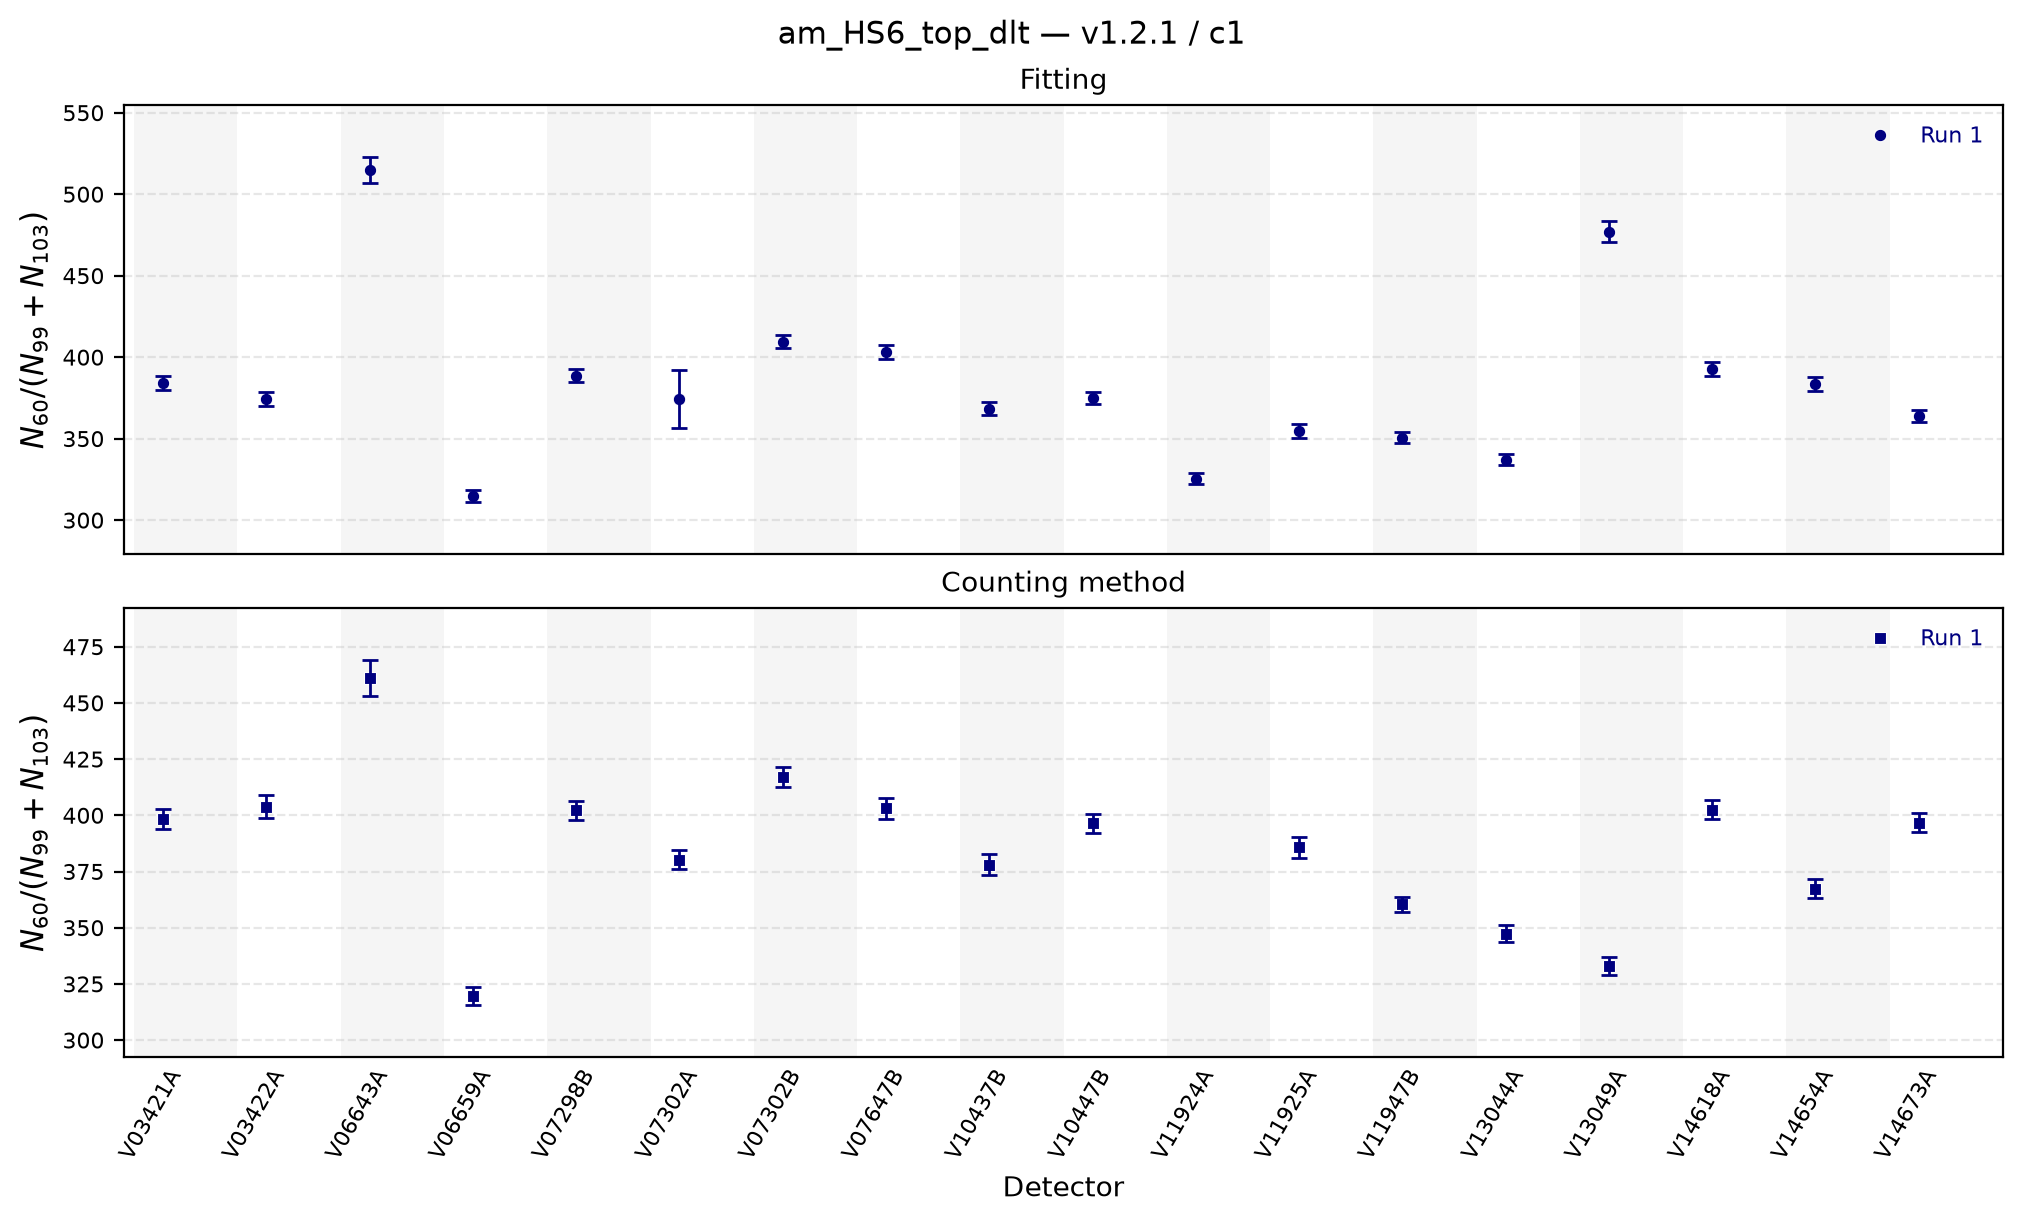

In [76]:


# ============================================================
# ONE FIGURE PER MEASUREMENT
# TWO PANELS: FIT AND COUNTING
# ============================================================

method_settings = [
    ("fit", "Fitting", "o"),
    ("counting", "Counting method", "s"),
]

for measurement, results in results_by_measurement.items():

    fig, axes = plt.subplots(
        2,
        1,
        figsize=(10, 6),
        sharex=True,
        layout="constrained",
        dpi=200,
    )

    for ax, (method, title, marker) in zip(axes, method_settings):

        # Bande alternate per distinguere i detector.
        for index in range(len(detectors)):
            if index % 2 == 0:
                ax.axvspan(
                    index - 0.5,
                    index + 0.5,
                    color="0.96",
                    linewidth=0,
                    zorder=0,
                )

        any_points = False

        for run in runs:
            x, y, errors = [], [], []

            for detector in detectors:
                record = (results.get(detector) or {}).get(run) or {}

                value, error = get_ratio(record, method)

                if value is None:
                    continue

                x.append(positions[detector] + run_offsets[run])
                y.append(value)
                errors.append(error if error is not None else np.nan)

                if error is None:
                    print(
                        f"{measurement}/{detector}/{run}: "
                        f"incertezza del rapporto {method} non disponibile."
                    )

            if not x:
                continue

            any_points = True

            x = np.asarray(x, dtype=float)
            y = np.asarray(y, dtype=float)
            errors = np.asarray(errors, dtype=float)

            # Mostra tutti i punti, anche senza incertezza disponibile.
            ax.plot(
                x,
                y,
                linestyle="none",
                marker=marker,
                markersize=4.5,
                color=run_colors[run],
                markeredgecolor="white",
                markeredgewidth=0.4,
                label=f"Run {int(run[3:])}",
                zorder=3,
            )

            valid_errors = np.isfinite(errors)

            ax.errorbar(
                x[valid_errors],
                y[valid_errors],
                yerr=errors[valid_errors],
                fmt="none",
                ecolor=run_colors[run],
                elinewidth=1,
                capsize=3,
                capthick=1,
                zorder=4,
            )

        if not any_points:
            ax.text(
                0.5, 0.5,
                "Nessun rapporto disponibile",
                transform=ax.transAxes,
                ha="center",
                va="center",
            )

        ax.set_title(title, fontsize=10)

        ax.set_ylabel(
            r"$N_{60}/(N_{99}+N_{103})$",
            fontsize=11,
        )

        ax.set_xlim(-0.6, len(detectors) - 0.4)
        ax.set_axisbelow(True)
        ax.grid(axis="y", linestyle="--", alpha=0.3)
        ax.tick_params(axis="both", labelsize=8)
        ax.tick_params(axis="x", length=0)
        ax.margins(y=0.15)

        if any_points:
            ax.legend(
                loc="best",
                ncol=3,
                frameon=False,
                fontsize=8,
                labelcolor="linecolor",
            )

    axes[-1].set_xticks(np.arange(len(detectors)))
    axes[-1].set_xticklabels(
        detectors,
        rotation=60,
        ha="right",
        fontsize=8,
    )
    axes[-1].set_xlabel("Detector")

    fig.suptitle(
        f"{measurement} — {data_version} / {data_campaign}",
        fontsize=11,
    )

    if save_plots:
        output_path = output_dir / (
            f"{measurement}_ratios_fit_counting_vs_detector.png"
        )

        fig.savefig(
            output_path,
            dpi=300,
            bbox_inches="tight",
            facecolor="white",
        )

        print(f"Plot salvato: {output_path}")

    plt.show()
    plt.close(fig)

Plot salvato: /global/u2/r/ritaferi/HADES_DATA/O60_experimental_pygama/v1.2.1/c1/comparison_measurements/am_HS1_top_dlt_fitting_vs_counting.png


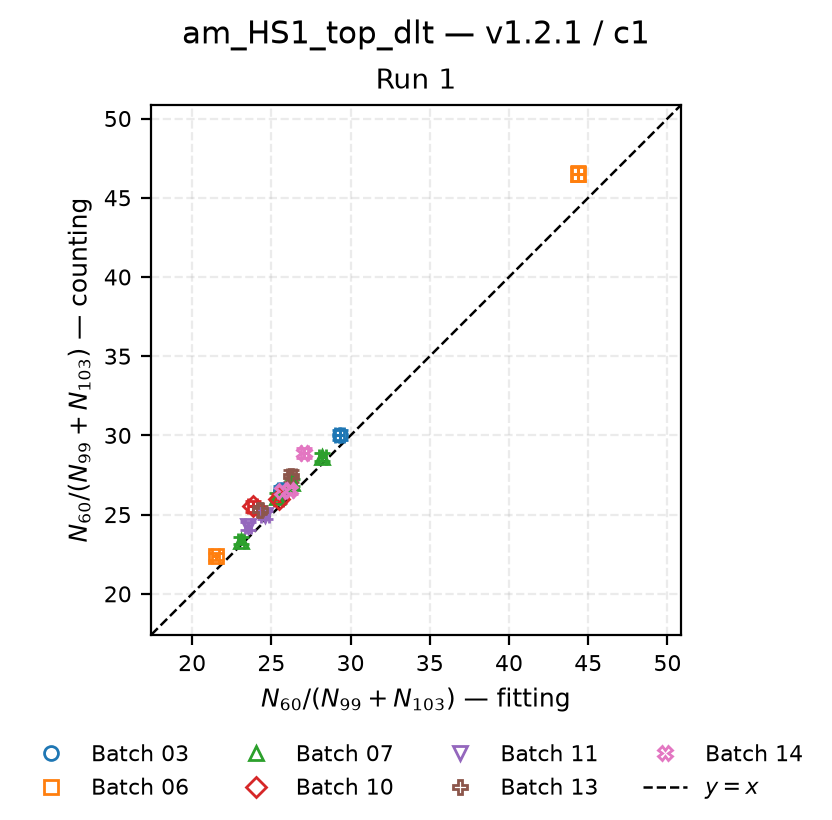

Plot salvato: /global/u2/r/ritaferi/HADES_DATA/O60_experimental_pygama/v1.2.1/c1/comparison_measurements/am_HS6_top_dlt_fitting_vs_counting.png


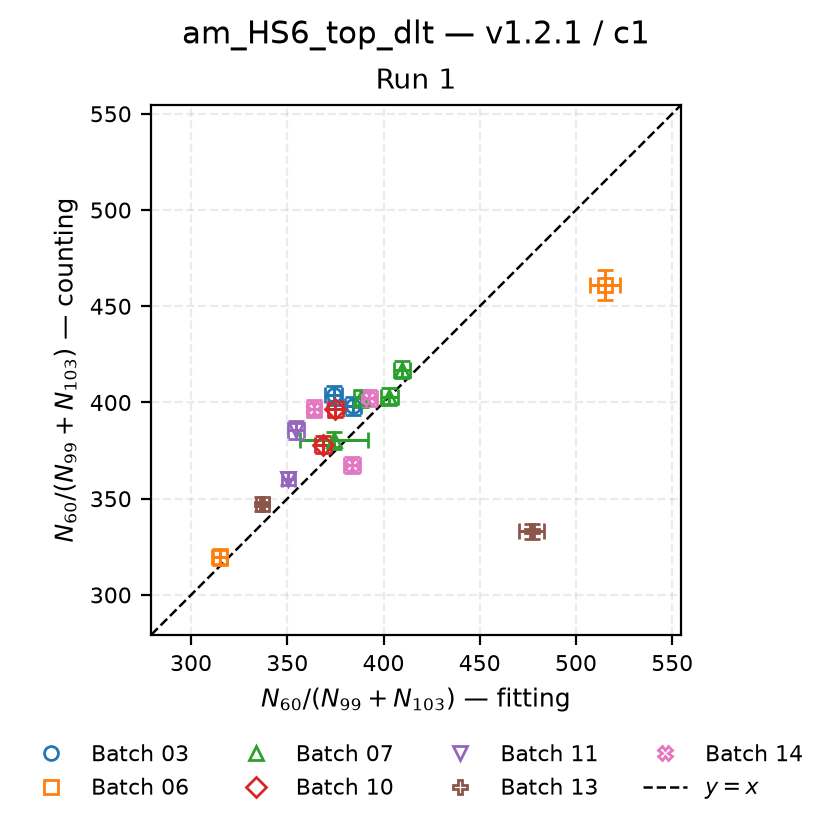

In [77]:

def get_batch(detector):
    match = re.search(r"\d{2}", detector)
    return match.group() if match else "Unknown"


batches = sorted({
    get_batch(detector)
    for results in results_by_measurement.values()
    for detector in results
})

colors = plt.colormaps["tab10"].colors
markers = ["o", "s", "^", "D", "v", "P", "X", "<", ">", "*"]

batch_styles = {
    batch: {
        "color": colors[index % len(colors)],
        "marker": markers[index % len(markers)],
    }
    for index, batch in enumerate(batches)
}


# ============================================================
# FITTING VS COUNTING — BOTH MEASUREMENTS
# ============================================================

for measurement, results in results_by_measurement.items():

    fig, axes = plt.subplots(
        1,
        len(runs),
        figsize=(12, 4),
        squeeze=False,
        layout="constrained",
        dpi=200,
    )

    shown_batches = set()

    for ax, run in zip(axes[0], runs):
        points = []

        for detector, detector_runs in sorted(results.items()):
            record = detector_runs.get(run) or {}

            x, xerr = get_ratio(record, "fit")
            y, yerr = get_ratio(record, "counting")

            if x is None or y is None:
                continue

            points.append({
                "batch": get_batch(detector),
                "x": x,
                "y": y,
                "xerr": xerr,
                "yerr": yerr,
            })

        ax.set_title(f"Run {int(run[3:])}", fontsize=10)
        ax.set_xlabel(
            r"$N_{60}/(N_{99}+N_{103})$ — fitting",
            fontsize=9,
        )
        ax.set_ylabel(
            r"$N_{60}/(N_{99}+N_{103})$ — counting",
            fontsize=9,
        )

        if not points:
            ax.text(
                0.5, 0.5,
                "Nessun risultato comune",
                transform=ax.transAxes,
                ha="center",
                va="center",
                fontsize=9,
            )
            continue

        lower_limits = []
        upper_limits = []

        for point in points:
            batch = point["batch"]
            style = batch_styles[batch]
            shown_batches.add(batch)

            x, y = point["x"], point["y"]
            xerr, yerr = point["xerr"], point["yerr"]

            ax.errorbar(
                x,
                y,
                xerr=xerr,
                yerr=yerr,
                fmt=style["marker"],
                linestyle="none",
                color=style["color"],
                ecolor=style["color"],
                markerfacecolor="none",
                markeredgewidth=1,
                markersize=5,
                elinewidth=1.1,
                capsize=3,
                capthick=1,
                zorder=3,
            )

            lower_limits.extend([
                x - (xerr if xerr is not None else 0),
                y - (yerr if yerr is not None else 0),
            ])
            upper_limits.extend([
                x + (xerr if xerr is not None else 0),
                y + (yerr if yerr is not None else 0),
            ])

        low = min(lower_limits)
        high = max(upper_limits)

        span = high - low
        margin = (
            0.15 * span
            if span > 0
            else max(abs(low) * 0.1, 1.0)
        )
        limits = (low - margin, high + margin)

        ax.plot(
            limits,
            limits,
            color="black",
            linestyle="--",
            linewidth=0.9,
            zorder=1,
        )

        ax.set_xlim(*limits)
        ax.set_ylim(*limits)
        ax.set_aspect("equal", adjustable="box")
        ax.grid(alpha=0.25, linestyle="--")
        ax.set_axisbelow(True)
        ax.tick_params(labelsize=8)

    handles = [
        Line2D(
            [], [],
            marker=batch_styles[batch]["marker"],
            color=batch_styles[batch]["color"],
            markerfacecolor="none",
            linestyle="none",
            markersize=5,
            label=f"Batch {batch}",
        )
        for batch in sorted(shown_batches)
    ]

    handles.append(
        Line2D(
            [], [],
            color="black",
            linestyle="--",
            linewidth=0.9,
            label=r"$y=x$",
        )
    )

    fig.suptitle(
        f"{measurement} — {data_version} / {data_campaign}",
        fontsize=11,
    )

    fig.legend(
        handles=handles,
        loc="outside lower center",
        ncol=4,
        frameon=False,
        fontsize=8,
    )

    if save_plots:
        output_path = output_dir / (
            f"{measurement}_fitting_vs_counting.png"
        )

        fig.savefig(
            output_path,
            dpi=300,
            bbox_inches="tight",
            facecolor="white",
        )

        print(f"Plot salvato: {output_path}")

    plt.show()
    plt.close(fig)

In [78]:
import re
from collections.abc import Mapping
from matplotlib.lines import Line2D


# ============================================================
# HELPERS
# ============================================================

def value_error(item):
    if isinstance(item, Mapping):
        value = finite_number(item.get("value"))
        error = finite_number(item.get("error"))
    else:
        value = finite_number(item)
        error = None

    if error is not None and error < 0:
        error = None

    return value, error


def get_fitted_n60(record):
    """Legge l'area gaussiana N60 e la sua incertezza."""
    fit = record.get("fit_60") or {}

    # Possibili campi espliciti.
    for key in ("N60", "area_peak", "area_59"):
        if key not in fit:
            continue

        value, error = value_error(fit[key])

        if error is None:
            error = finite_number(
                fit.get(f"{key}_error")
            )

        if value is not None:
            return value, (
                error if error is not None and error >= 0 else None
            )

    parameters = fit.get("parameters")

    # Parametri salvati come dizionario.
    if isinstance(parameters, Mapping):
        for name in ("N60", "A60", "A_G", "area"):
            if name not in parameters:
                continue

            value, error = value_error(parameters[name])

            if error is None:
                errors = fit.get("errors") or {}
                if isinstance(errors, Mapping):
                    error = finite_number(errors.get(name))

            return value, (
                error if error is not None and error >= 0 else None
            )

    # Parametri salvati come array.
    if isinstance(parameters, (list, tuple, np.ndarray)):
        names = (
            fit.get("parameter_order")
            or fit.get("parameter_names")
            or []
        )

        if names:
            matching = [
                name for name in ("N60", "A60", "A_G", "area")
                if name in names
            ]

            if not matching:
                return None, None

            index = names.index(matching[0])
        else:
            # Nel modello discusso N60 è il primo parametro.
            index = 0

        if len(parameters) <= index:
            return None, None

        value = finite_number(parameters[index])
        errors = fit.get("errors")
        error = None

        if isinstance(errors, (list, tuple, np.ndarray)):
            if len(errors) > index:
                error = finite_number(errors[index])

        return value, (
            error if error is not None and error >= 0 else None
        )

    return None, None


def get_sp_ratio(record, method):
    dlf = record.get("DLF") or {}

    if method == "counting":
        return value_error(dlf.get("ratio") or {})

    if method != "fit":
        raise ValueError(f"Metodo non riconosciuto: {method}")

    sp, sp_error = value_error(dlf.get("SP_net"))
    n60, n60_error = get_fitted_n60(record)

    if sp is None or n60 is None or n60 <= 0:
        return None, None

    ratio = sp / n60

    if sp_error is None or n60_error is None:
        return ratio, None

    variance = (
        sp_error**2 / n60**2
        + sp**2 * n60_error**2 / n60**4
    )

    return ratio, np.sqrt(variance)


def get_batch(detector):
    match = re.search(r"\d{2}", detector)
    return match.group() if match else "Unknown"



Plot salvato: /global/u2/r/ritaferi/HADES_DATA/O60_experimental_pygama/v1.2.1/c1/comparison_measurements/am_HS1_top_dlt_SP_N60_vs_detector.png


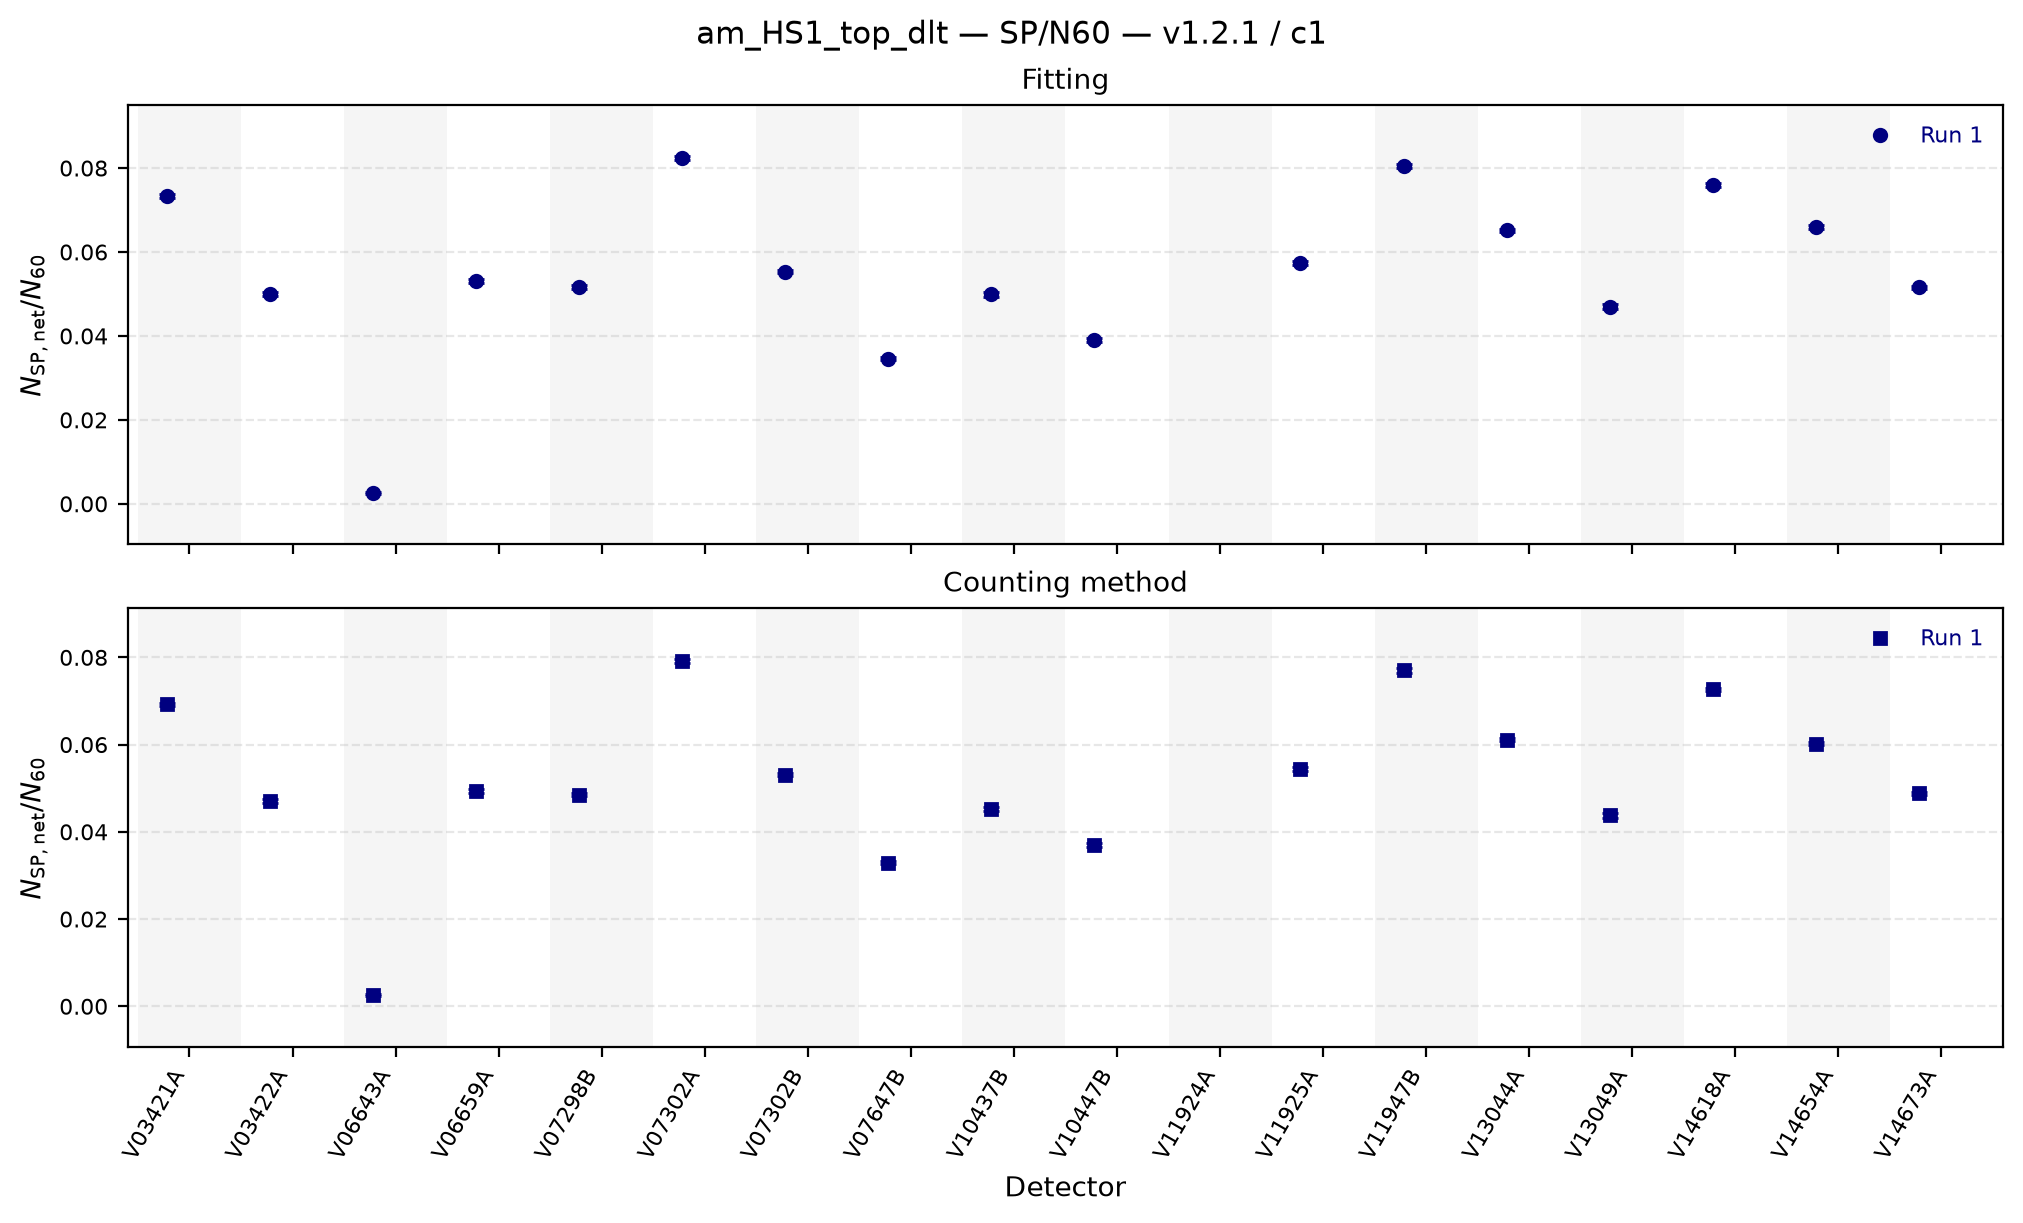

Plot salvato: /global/u2/r/ritaferi/HADES_DATA/O60_experimental_pygama/v1.2.1/c1/comparison_measurements/am_HS6_top_dlt_SP_N60_vs_detector.png


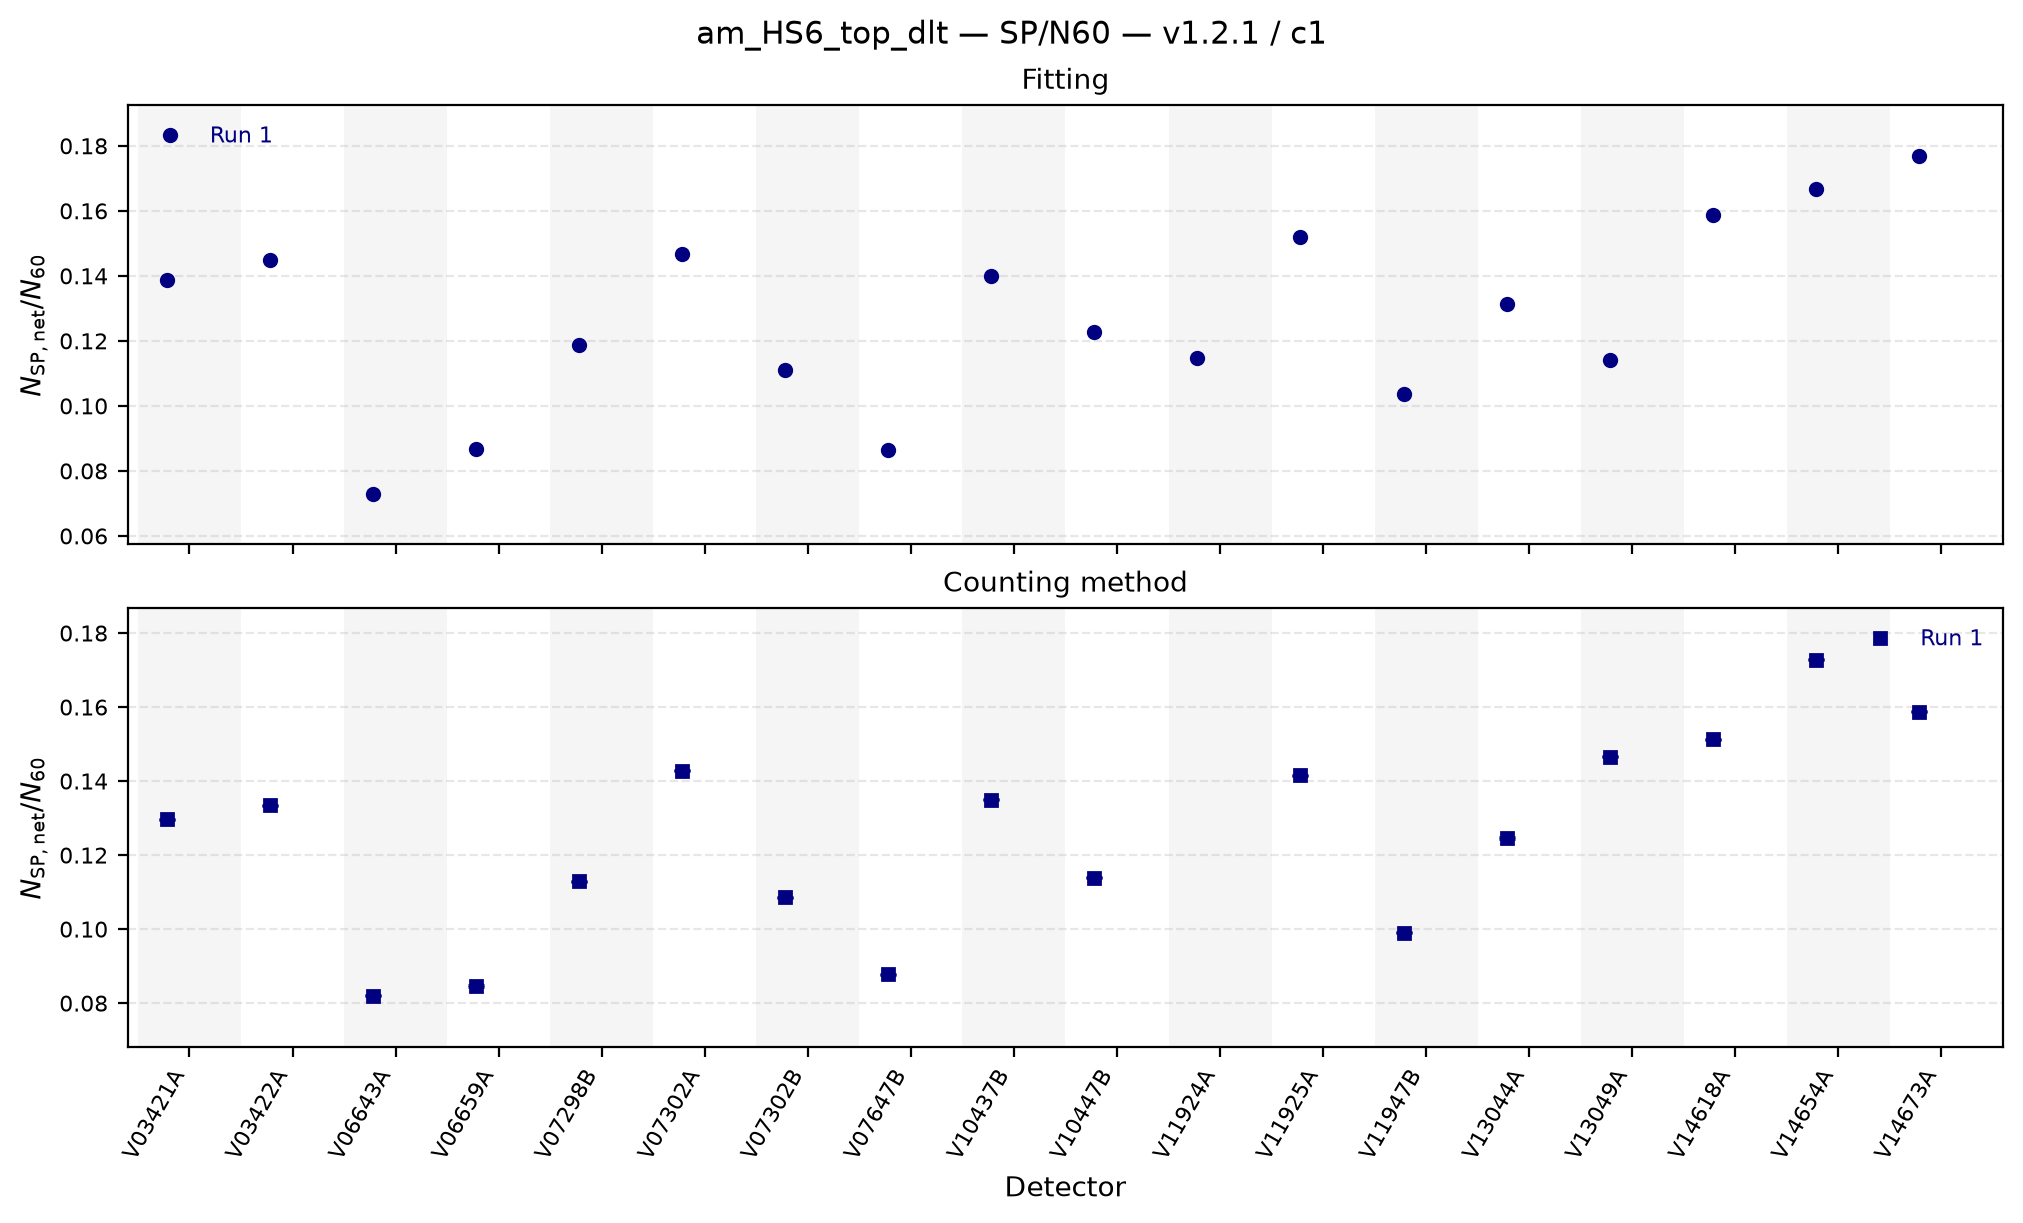

Plot salvato: /global/u2/r/ritaferi/HADES_DATA/O60_experimental_pygama/v1.2.1/c1/comparison_measurements/am_HS1_top_dlt_SP_N60_fitting_vs_counting.png


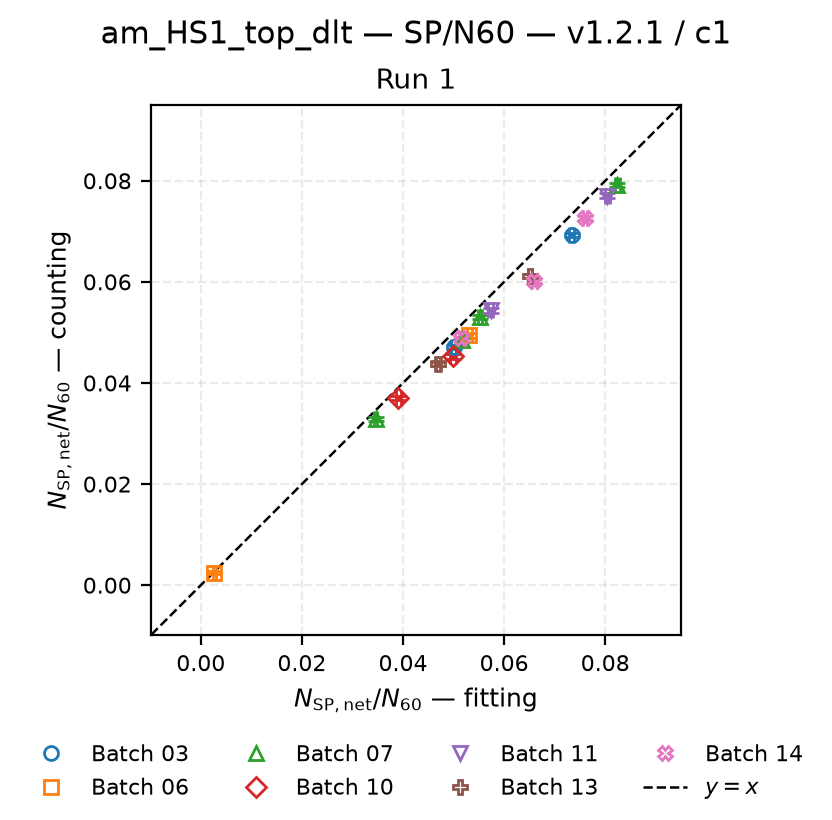

Plot salvato: /global/u2/r/ritaferi/HADES_DATA/O60_experimental_pygama/v1.2.1/c1/comparison_measurements/am_HS6_top_dlt_SP_N60_fitting_vs_counting.png


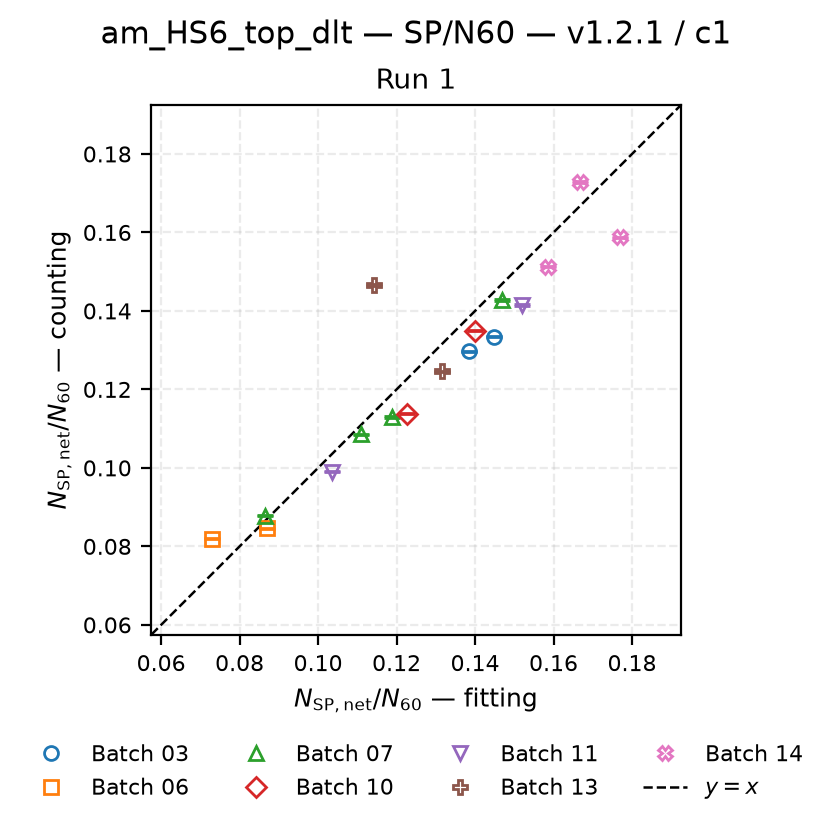

In [79]:

# ============================================================
# COMMON BATCH STYLES
# ============================================================

batches = sorted({
    get_batch(detector)
    for results in results_by_measurement.values()
    for detector in results
})

colors = plt.colormaps["tab10"].colors
markers = ["o", "s", "^", "D", "v", "P", "X", "<", ">", "*"]

batch_styles = {
    batch: {
        "color": colors[index % len(colors)],
        "marker": markers[index % len(markers)],
    }
    for index, batch in enumerate(batches)
}

sp_detectors = sorted({
    detector
    for results in results_by_measurement.values()
    for detector, detector_runs in results.items()
    if any(
        get_sp_ratio(detector_runs.get(run) or {}, method)[0]
        is not None
        for run in runs
        for method in ("fit", "counting")
    )
})

if not sp_detectors:
    raise ValueError(
        "Nessun rapporto SP/N60 disponibile: "
        "controlla i campi DLF e fit_60."
    )

sp_positions = {
    detector: index
    for index, detector in enumerate(sp_detectors)
}


# ============================================================
# ONE FIGURE PER MEASUREMENT: RATIO VS DETECTOR
# ============================================================

for measurement, results in results_by_measurement.items():

    fig, axes = plt.subplots(
        2, 1,
        figsize=(10, 6),
        sharex=True,
        layout="constrained",
        dpi=200,
    )

    for ax, method, title, marker in zip(
        axes,
        ("fit", "counting"),
        ("Fitting", "Counting method"),
        ("o", "s"),
    ):
        for index in range(len(sp_detectors)):
            if index % 2 == 0:
                ax.axvspan(
                    index - 0.5,
                    index + 0.5,
                    color="0.96",
                    linewidth=0,
                    zorder=0,
                )

        for run in runs:
            x, y, errors = [], [], []

            for detector in sp_detectors:
                record = (results.get(detector) or {}).get(run) or {}
                value, error = get_sp_ratio(record, method)

                if value is None:
                    continue

                x.append(sp_positions[detector] + run_offsets[run])
                y.append(value)
                errors.append(
                    error if error is not None else np.nan
                )

            if not x:
                continue

            x = np.asarray(x)
            y = np.asarray(y)
            errors = np.asarray(errors)

            ax.plot(
                x, y,
                linestyle="none",
                marker=marker,
                markersize=4.5,
                color=run_colors[run],
                label=f"Run {int(run[3:])}",
                zorder=3,
            )

            valid = np.isfinite(errors)

            ax.errorbar(
                x[valid],
                y[valid],
                yerr=errors[valid],
                fmt="none",
                ecolor=run_colors[run],
                elinewidth=1,
                capsize=3,
                zorder=4,
            )

        ax.set_title(title, fontsize=10)
        ax.set_ylabel(r"$N_{\mathrm{SP,net}}/N_{60}$")
        ax.set_xlim(-0.6, len(sp_detectors) - 0.4)
        ax.grid(axis="y", linestyle="--", alpha=0.3)
        ax.set_axisbelow(True)
        ax.tick_params(labelsize=8)
        ax.margins(y=0.15)

        handles, labels = ax.get_legend_handles_labels()
        if handles:
            ax.legend(
                frameon=False,
                ncol=3,
                fontsize=8,
                labelcolor="linecolor",
            )

    axes[-1].set_xticks(np.arange(len(sp_detectors)))
    axes[-1].set_xticklabels(
        sp_detectors,
        rotation=60,
        ha="right",
        fontsize=8,
    )
    axes[-1].set_xlabel("Detector")

    fig.suptitle(
        f"{measurement} — SP/N60 — {data_version} / {data_campaign}",
        fontsize=11,
    )

    if save_plots:
        output_path = output_dir / (
            f"{measurement}_SP_N60_vs_detector.png"
        )
        fig.savefig(
            output_path,
            dpi=300,
            bbox_inches="tight",
            facecolor="white",
        )
        print(f"Plot salvato: {output_path}")

    plt.show()
    plt.close(fig)


# ============================================================
# ONE FIGURE PER MEASUREMENT: FITTING VS COUNTING
# ============================================================

for measurement, results in results_by_measurement.items():

    fig, axes = plt.subplots(
        1, len(runs),
        figsize=(12, 4),
        squeeze=False,
        layout="constrained",
        dpi=200,
    )

    shown_batches = set()

    for ax, run in zip(axes[0], runs):
        points = []

        for detector, detector_runs in sorted(results.items()):
            record = detector_runs.get(run) or {}

            x, xerr = get_sp_ratio(record, "fit")
            y, yerr = get_sp_ratio(record, "counting")

            if x is None or y is None:
                continue

            points.append({
                "batch": get_batch(detector),
                "x": x,
                "y": y,
                "xerr": xerr,
                "yerr": yerr,
            })

        ax.set_title(f"Run {int(run[3:])}", fontsize=10)
        ax.set_xlabel(
            r"$N_{\mathrm{SP,net}}/N_{60}$ — fitting",
            fontsize=9,
        )
        ax.set_ylabel(
            r"$N_{\mathrm{SP,net}}/N_{60}$ — counting",
            fontsize=9,
        )

        if not points:
            ax.text(
                0.5, 0.5,
                "Nessun risultato comune",
                transform=ax.transAxes,
                ha="center",
                va="center",
            )
            continue

        lower, upper = [], []

        for point in points:
            batch = point["batch"]
            style = batch_styles[batch]
            shown_batches.add(batch)

            x, y = point["x"], point["y"]
            xerr, yerr = point["xerr"], point["yerr"]

            ax.errorbar(
                x, y,
                xerr=xerr,
                yerr=yerr,
                fmt=style["marker"],
                linestyle="none",
                color=style["color"],
                ecolor=style["color"],
                markerfacecolor="none",
                markersize=5,
                markeredgewidth=1,
                elinewidth=1.1,
                capsize=3,
                zorder=3,
            )

            lower.extend([
                x - (xerr if xerr is not None else 0),
                y - (yerr if yerr is not None else 0),
            ])
            upper.extend([
                x + (xerr if xerr is not None else 0),
                y + (yerr if yerr is not None else 0),
            ])

        low, high = min(lower), max(upper)
        span = high - low
        margin = (
            0.15 * span
            if span > 0
            else max(abs(low) * 0.1, 0.01)
        )
        limits = (low - margin, high + margin)

        ax.plot(
            limits, limits,
            color="black",
            linestyle="--",
            linewidth=0.9,
            zorder=1,
        )

        ax.set_xlim(*limits)
        ax.set_ylim(*limits)
        ax.set_aspect("equal", adjustable="box")
        ax.grid(alpha=0.25, linestyle="--")
        ax.set_axisbelow(True)
        ax.tick_params(labelsize=8)

    handles = [
        Line2D(
            [], [],
            marker=batch_styles[batch]["marker"],
            color=batch_styles[batch]["color"],
            markerfacecolor="none",
            linestyle="none",
            markersize=5,
            label=f"Batch {batch}",
        )
        for batch in sorted(shown_batches)
    ]

    handles.append(
        Line2D(
            [], [],
            color="black",
            linestyle="--",
            linewidth=0.9,
            label=r"$y=x$",
        )
    )

    fig.suptitle(
        f"{measurement} — SP/N60 — {data_version} / {data_campaign}",
        fontsize=11,
    )

    fig.legend(
        handles=handles,
        loc="outside lower center",
        ncol=4,
        frameon=False,
        fontsize=8,
    )

    if save_plots:
        output_path = output_dir / (
            f"{measurement}_SP_N60_fitting_vs_counting.png"
        )
        fig.savefig(
            output_path,
            dpi=300,
            bbox_inches="tight",
            facecolor="white",
        )
        print(f"Plot salvato: {output_path}")

    plt.show()
    plt.close(fig)

Caricato: /global/u2/r/ritaferi/HADES_DATA/O60_experimental_pygama/v1.2.1/c1/am_HS1_top_dlt/all_results.json
Caricato: /global/u2/r/ritaferi/HADES_DATA/O60_experimental_pygama/v1.2.1/c1/am_HS6_top_dlt/all_results.json
Plot salvato: /global/u2/r/ritaferi/HADES_DATA/O60_experimental_pygama/v1.2.1/c1/comparison_measurements/am_HS1_top_dlt_run0001_counting_O60_vs_SP_N60.png


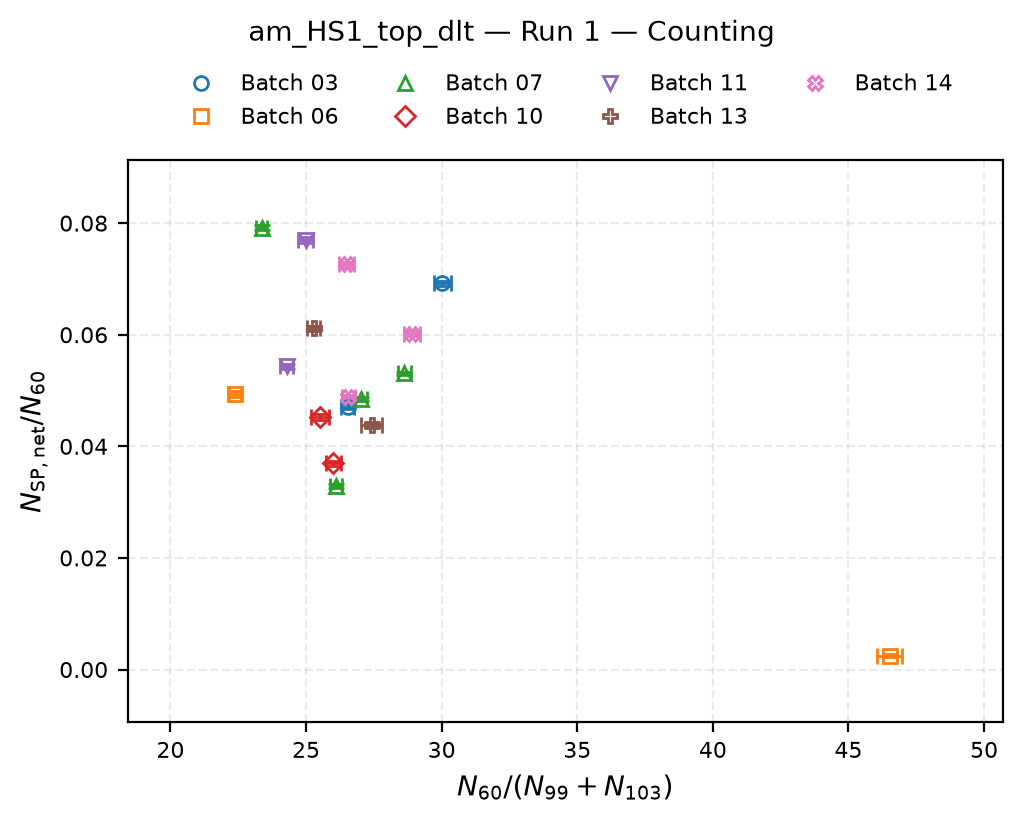

Plot salvato: /global/u2/r/ritaferi/HADES_DATA/O60_experimental_pygama/v1.2.1/c1/comparison_measurements/am_HS1_top_dlt_run0001_fitting_O60_vs_SP_N60.png


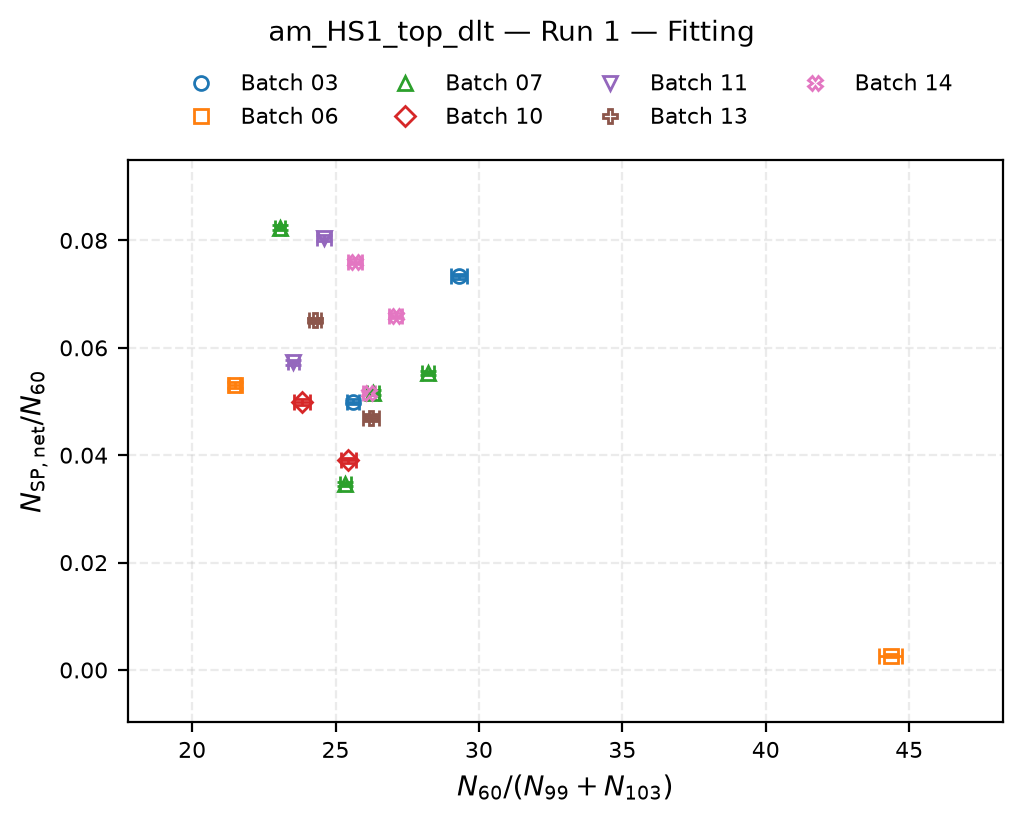

Skipping am_HS6_top_dlt/V11924A/run0001: rapporti counting non disponibili.
Plot salvato: /global/u2/r/ritaferi/HADES_DATA/O60_experimental_pygama/v1.2.1/c1/comparison_measurements/am_HS6_top_dlt_run0001_counting_O60_vs_SP_N60.png


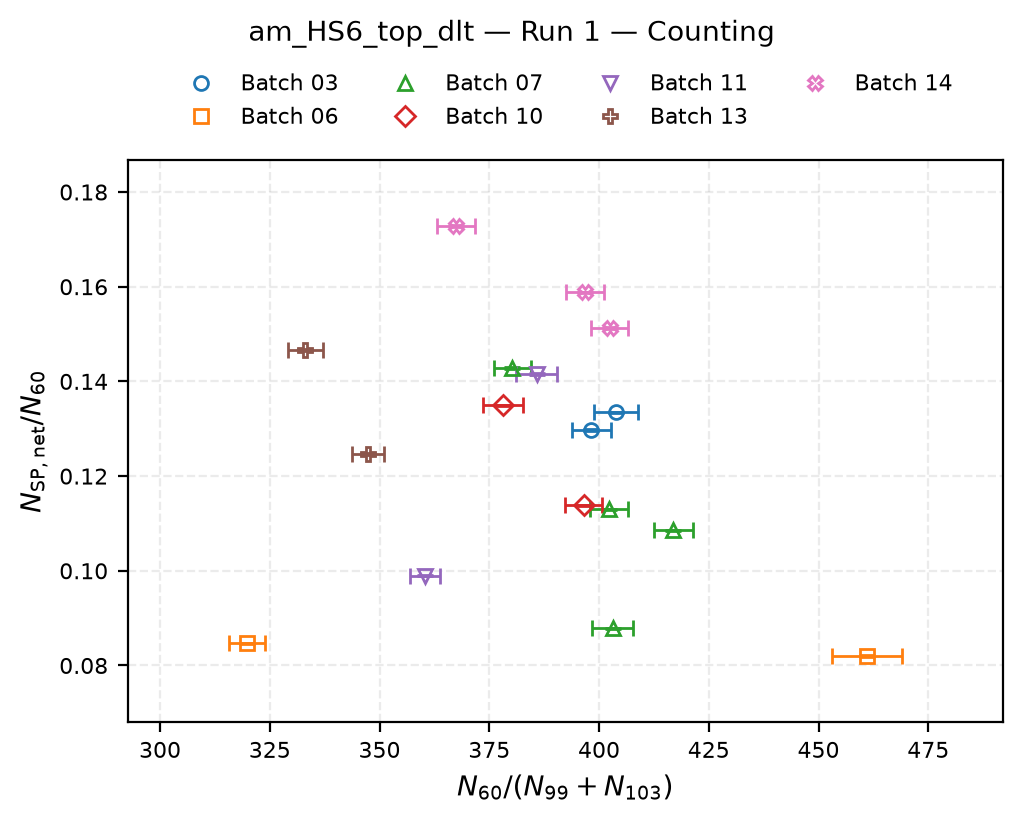

Plot salvato: /global/u2/r/ritaferi/HADES_DATA/O60_experimental_pygama/v1.2.1/c1/comparison_measurements/am_HS6_top_dlt_run0001_fitting_O60_vs_SP_N60.png


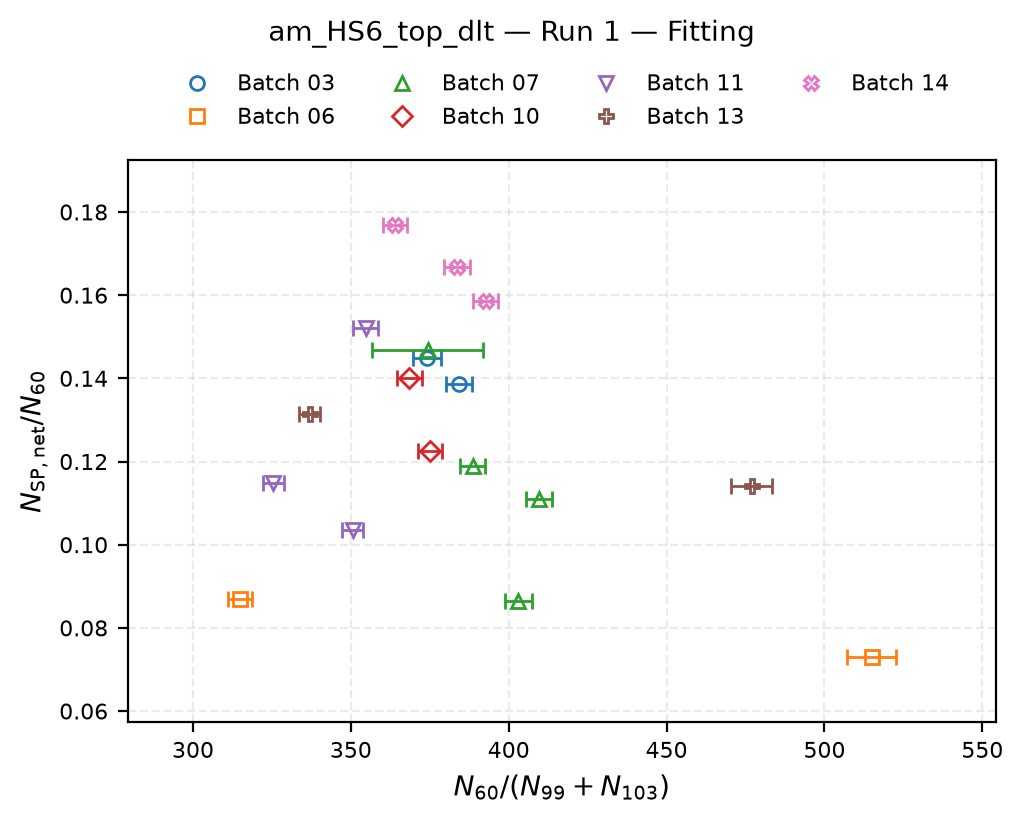

In [80]:
from pathlib import Path
import json
import re

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D


# ============================================================
# CONFIGURATION
# ============================================================

data_version = "v1.2.1"
data_campaign = "c1"

measurements = [
    "am_HS1_top_dlt",
    "am_HS6_top_dlt",
]

run = "run0001"

results_root = (
    Path("/global/u2/r/ritaferi/HADES_DATA")
    / "O60_experimental_pygama"
    / data_version
    / data_campaign
)

save_plots = True
output_dir = results_root / "comparison_measurements"

if save_plots:
    output_dir.mkdir(parents=True, exist_ok=True)


# ============================================================
# HELPERS
# ============================================================

def finite_number(value):
    try:
        value = float(value)
    except (TypeError, ValueError):
        return None

    return value if np.isfinite(value) else None


def read_value_error(item):
    if not isinstance(item, dict):
        return None, None

    value = finite_number(item.get("value"))
    error = finite_number(item.get("error"))

    if error is not None and error < 0:
        error = None

    return value, error


def get_batch(detector):
    match = re.search(r"\d{2}", detector)
    return match.group() if match else "Unknown"


def get_fit_n60(record):
    fit = record.get("fit_60") or {}
    parameters = fit.get("parameters")
    errors = fit.get("errors")

    if isinstance(parameters, dict):
        item = parameters.get("N60")

        if isinstance(item, dict):
            value, error = read_value_error(item)
        else:
            value = finite_number(item)
            error = None

        if error is None and isinstance(errors, dict):
            error = finite_number(errors.get("N60"))

    elif isinstance(parameters, list) and parameters:
        names = (
            fit.get("parameter_order")
            or fit.get("parameter_names")
            or []
        )

        if names and "N60" not in names:
            return None, None

        index = names.index("N60") if names else 0

        if index >= len(parameters):
            return None, None

        value = finite_number(parameters[index])
        error = (
            finite_number(errors[index])
            if isinstance(errors, list) and index < len(errors)
            else None
        )

    else:
        return None, None

    if error is not None and error < 0:
        error = None

    return value, error


def get_observables(record, method):
    dlf = record.get("DLF") or {}

    if method == "counting":
        ratio_x = (
            record.get("ratio_counting")
            or (record.get("counting_method") or {}).get("ratio")
            or {}
        )

        x, xerr = read_value_error(ratio_x)
        y, yerr = read_value_error(dlf.get("ratio"))

    elif method == "fitting":
        x, xerr = read_value_error(record.get("ratio"))

        sp, sp_error = read_value_error(dlf.get("SP_net"))
        n60, n60_error = get_fit_n60(record)

        if sp is None or n60 is None or n60 <= 0:
            return None

        y = sp / n60

        # SP e picco a 60 keV occupano finestre separate.
        yerr = (
            np.sqrt(
                sp_error**2 / n60**2
                + sp**2 * n60_error**2 / n60**4
            )
            if sp_error is not None and n60_error is not None
            else None
        )

    else:
        raise ValueError("Metodo non riconosciuto.")

    if x is None or y is None:
        return None

    return {
        "x": x,
        "y": y,
        "xerr": xerr,
        "yerr": yerr,
    }


# ============================================================
# LOAD DICTIONARIES
# ============================================================

results_by_measurement = {}

for measurement in measurements:
    path = results_root / measurement / "all_results.json"

    if not path.is_file():
        print(f"File mancante: {path}")
        continue

    with path.open(encoding="utf-8") as stream:
        results_by_measurement[measurement] = json.load(stream)

    print(f"Caricato: {path}")

if not results_by_measurement:
    raise FileNotFoundError("Nessun all_results.json trovato.")


# ============================================================
# SAME BATCH STYLES IN ALL PLOTS
# ============================================================

batches = sorted({
    get_batch(detector)
    for results in results_by_measurement.values()
    for detector in results
})

colors = plt.colormaps["tab10"].colors
markers = ["o", "s", "^", "D", "v", "P", "X", "<", ">", "*"]

batch_styles = {
    batch: {
        "color": colors[index % len(colors)],
        "marker": markers[index % len(markers)],
    }
    for index, batch in enumerate(batches)
}


# ============================================================
# RUN 1 ONLY — COUNTING AND FITTING
# ============================================================

for measurement, results in results_by_measurement.items():
    for method in ("counting", "fitting"):

        points = []

        for detector, detector_runs in sorted(results.items()):
            record = detector_runs.get(run) or {}

            if not record:
                continue

            point = get_observables(record, method)

            if point is None:
                print(
                    f"Skipping {measurement}/{detector}/{run}: "
                    f"rapporti {method} non disponibili."
                )
                continue

            point["batch"] = get_batch(detector)
            points.append(point)

        if not points:
            print(f"{measurement}/{run}/{method}: nessun punto.")
            continue

        fig, ax = plt.subplots(
            figsize=(5, 4),
            layout="constrained",
            dpi=200,
        )

        shown_batches = set()

        for point in points:
            batch = point["batch"]
            style = batch_styles[batch]
            shown_batches.add(batch)

            ax.errorbar(
                point["x"],
                point["y"],
                xerr=point["xerr"],
                yerr=point["yerr"],
                fmt=style["marker"],
                linestyle="none",
                color=style["color"],
                ecolor=style["color"],
                markerfacecolor="none",
                markersize=5,
                markeredgewidth=1,
                elinewidth=1,
                capsize=3,
                zorder=3,
            )

        handles = [
            Line2D(
                [], [],
                marker=batch_styles[batch]["marker"],
                color=batch_styles[batch]["color"],
                markerfacecolor="none",
                linestyle="none",
                markersize=5,
                label=f"Batch {batch}",
            )
            for batch in sorted(shown_batches)
        ]

        ax.legend(
            handles=handles,
            loc="lower center",
            bbox_to_anchor=(0.5, 1.02),
            ncol=4,
            frameon=False,
            fontsize=8,
        )

        ax.set_xlabel(r"$N_{60}/(N_{99}+N_{103})$")
        ax.set_ylabel(r"$N_{\mathrm{SP,net}}/N_{60}$")
        #ax.set_xlim(20,32)

        fig.suptitle(
            f"{measurement} — Run 1 — {method.capitalize()}",
            fontsize=10,
        )

        ax.grid(alpha=0.25, linestyle="--")
        ax.set_axisbelow(True)
        ax.tick_params(labelsize=8)
        ax.margins(x=0.15, y=0.15)

        if save_plots:
            output_path = output_dir / (
                f"{measurement}_{run}_{method}_O60_vs_SP_N60.png"
            )

            fig.savefig(
                output_path,
                dpi=300,
                bbox_inches="tight",
                facecolor="white",
            )
            print(f"Plot salvato: {output_path}")

        plt.show()
        plt.close(fig)